In [1]:
# Loading the dataset using pandas
import numpy as np
import pandas as pd
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats


# Load and Inspect

In [2]:
df = pd.read_csv('customer_shopping_behavior.csv')

In [3]:
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [5]:
# rows and cols in data (shape of data)
df.shape

(3900, 18)

In [6]:
df['Category'].value_counts()

Category
Clothing       1737
Accessories    1240
Footwear        599
Outerwear       324
Name: count, dtype: int64

In [7]:
df['Color'].value_counts()

Color
Olive        177
Yellow       174
Silver       173
Teal         172
Green        169
Black        167
Cyan         166
Violet       166
Gray         159
Maroon       158
Orange       154
Charcoal     153
Pink         153
Magenta      152
Blue         152
Purple       151
Peach        149
Red          148
Beige        147
Indigo       147
Lavender     147
Turquoise    145
White        142
Brown        141
Gold         138
Name: count, dtype: int64

In [8]:
# summary of the data
df.describe(include='all')

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
count,3900.000000,3900.000000,3900,3900,3900,3900.000000,3900,3900,3900,3900,3863.000000,3900,3900,3900,3900,3900.000000,3900,3900
unique,NaN,NaN,2,25,4,NaN,50,4,25,4,NaN,2,6,2,2,NaN,6,7
top,NaN,NaN,Male,Blouse,Clothing,NaN,Montana,M,Olive,Spring,NaN,No,Free Shipping,No,No,NaN,PayPal,Every 3 Months
freq,NaN,NaN,2652,171,1737,NaN,96,1755,177,999,NaN,2847,675,2223,2223,NaN,677,584
mean,1950.500000,44.068462,NaN,NaN,NaN,59.764359,NaN,NaN,NaN,NaN,3.750065,NaN,NaN,NaN,NaN,25.351538,NaN,NaN
std,1125.977353,15.207589,NaN,NaN,NaN,23.685392,NaN,NaN,NaN,NaN,0.716983,NaN,NaN,NaN,NaN,14.447125,NaN,NaN
min,1.000000,18.000000,NaN,NaN,NaN,20.000000,NaN,NaN,NaN,NaN,2.500000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,975.750000,31.000000,NaN,NaN,NaN,39.000000,NaN,NaN,NaN,NaN,3.100000,NaN,NaN,NaN,NaN,13.000000,NaN,NaN
50%,1950.500000,44.000000,NaN,NaN,NaN,60.000000,NaN,NaN,NaN,NaN,3.800000,NaN,NaN,NaN,NaN,25.000000,NaN,NaN
75%,2925.250000,57.000000,NaN,NaN,NaN,81.000000,NaN,NaN,NaN,NaN,4.400000,NaN,NaN,NaN,NaN,38.000000,NaN,NaN


# Data Quality

In [9]:
# checking if missing data or null values are present in the dataset
df.isnull().sum()

Customer ID                0
Age                        0
Gender                     0
Item Purchased             0
Category                   0
Purchase Amount (USD)      0
Location                   0
Size                       0
Color                      0
Season                     0
Review Rating             37
Subscription Status        0
Shipping Type              0
Discount Applied           0
Promo Code Used            0
Previous Purchases         0
Payment Method             0
Frequency of Purchases     0
dtype: int64

<Axes: ylabel='Review Rating'>

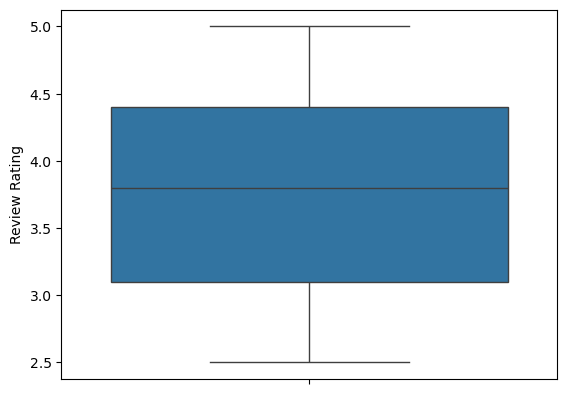

In [10]:
import seaborn as sns

sns.boxplot(df['Review Rating'])

In [11]:
# Imputing missing values in Review Rating column with the median rating of the product category

df['Review Rating'] = df.groupby('Category')['Review Rating'].transform(lambda x: x.fillna(x.median()))

In [12]:
df.isnull().sum()

Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64

In [13]:
# Checking for duplicate records
df.duplicated().sum()

np.int64(0)

In [14]:
# Renaming columns for better readability

df.columns = df.columns.str.lower()
df.columns = df.columns.str.replace(' ','_')
df = df.rename(columns = {'purchase_amount_(usd)':'purchase_amount'})

In [15]:
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'promo_code_used', 'previous_purchases',
       'payment_method', 'frequency_of_purchases'],
      dtype='object')

In [16]:
# create a new column age_group
age_bins = [17, 24, 34, 54, df['age'].max()]
age_labels = ["18-24","25-34","35-54","55+"]
df["age_group"] = pd.cut(df['age'], bins=age_bins, labels=age_labels, ordered=True)

In [17]:
df['age_group'].value_counts()

age_group
35-54    1481
55+      1178
25-34     755
18-24     486
Name: count, dtype: int64

In [18]:
df[['age','age_group']].sample(10)

,age,age_group
1024,28,25-34
1728,23,18-24
3045,42,35-54
3616,42,35-54
784,31,25-34
907,32,25-34
2087,54,35-54
81,67,55+
3398,54,35-54
2882,59,55+


In [19]:
df['shipping_type'].value_counts()

shipping_type
Free Shipping     675
Standard          654
Store Pickup      650
Next Day Air      648
Express           646
2-Day Shipping    627
Name: count, dtype: int64

In [20]:
df['frequency_of_purchases'].value_counts()

frequency_of_purchases
Every 3 Months    584
Annually          572
Quarterly         563
Monthly           553
Bi-Weekly         547
Fortnightly       542
Weekly            539
Name: count, dtype: int64

In [21]:
# create column frequency_of_purchases

frequency_mapping = {
    'Weekly': 7,
    'Bi-Weekly': 14,
    "Fortnightly": 14,
    'Monthly': 30,
    'Quarterly': 90,
    "Every 3 Months": 90,
    'Annually': 365
}

df['frequency_of_purchases_days'] = df['frequency_of_purchases'].map(frequency_mapping)

In [22]:
df[['frequency_of_purchases_days','frequency_of_purchases']].sample(10)

,frequency_of_purchases_days,frequency_of_purchases
3331,90,Quarterly
1564,90,Every 3 Months
2758,14,Bi-Weekly
316,30,Monthly
611,30,Monthly
1470,90,Every 3 Months
438,14,Fortnightly
3045,14,Bi-Weekly
2644,90,Every 3 Months
3802,30,Monthly


In [23]:
tier_bins = [0, 5, 20, 40, df['previous_purchases'].max()]
tier_labels = ["New","Returning","Loyal","VTP"]
df["loyalty_tire"] = pd.cut(df['previous_purchases'], bins=tier_bins, labels=tier_labels, ordered=True)

In [24]:
df['loyalty_tire'].value_counts()

loyalty_tire
Loyal        1574
Returning    1137
VTP           765
New           424
Name: count, dtype: int64

In [25]:
df[['previous_purchases','loyalty_tire']].sample(10)

,previous_purchases,loyalty_tire
1002,3,New
3022,23,Loyal
2213,18,Returning
2177,9,Returning
3660,13,Returning
406,13,Returning
655,19,Returning
1310,38,Loyal
3115,9,Returning
580,10,Returning


In [26]:
df[['discount_applied','promo_code_used']].sample(10)

,discount_applied,promo_code_used
1833,No,No
3832,No,No
2975,No,No
1559,Yes,Yes
2454,No,No
3181,No,No
3164,No,No
3136,No,No
1821,No,No
1699,No,No


In [27]:
# both shown same information
# Check for this data if we get discount only when we apply promo code

(df['discount_applied'] == df['promo_code_used']).all()

np.True_

In [28]:
# We don't need both columns
df = df.drop('promo_code_used', axis=1)

In [29]:
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'previous_purchases', 'payment_method',
       'frequency_of_purchases', 'age_group', 'frequency_of_purchases_days',
       'loyalty_tire'],
      dtype='object')

In [30]:
# checking if discount effect order value

discount_summary = df.groupby("discount_applied")["purchase_amount"].agg(
    count="count",
    mean="mean",
    std="std",
    median="median",
    q25=lambda x: np.percentile(x, 25),
    q75=lambda x: np.percentile(x, 75),
    min="min",
    max="max"
).round(2)

print("Purchase Amount Summary by Discount Applied:")
print(discount_summary, "\n")

Purchase Amount Summary by Discount Applied:
                  count   mean    std  median   q25   q75  min  max
discount_applied                                                   
No                 2223  60.13  23.74    60.0  39.0  81.0   20  100
Yes                1677  59.28  23.61    60.0  38.0  80.0   20  100 



The overall spend distribution is virtually unchanged: Both groups share the exact same median ($60.00), nearly identical middle spreads (IQR  of $38.00–$80.00 vs. $39.00–$81.00), and the same $20–$100 range, meaning discounts aren't pulling buyers into noticeably higher-priced carts.

In [31]:
# 2. Welch's two-sample t-test (H0: mean spend is equal with vs. without discount)
disc_yes = df.loc[df["discount_applied"] == "Yes", "purchase_amount"]
disc_no = df.loc[df["discount_applied"] == "No", "purchase_amount"]

t_stat, p_val = stats.ttest_ind(disc_yes, disc_no, equal_var=False)

print(f"Welch's t-statistic: {t_stat:.4f}")
print(f"p-value: {p_val:.4f}")

Welch's t-statistic: -1.1122
p-value: 0.2661


Discounts do not significantly change average order value

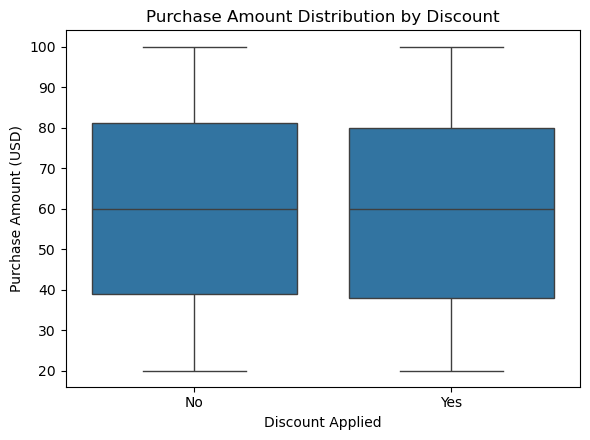

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4.5))

sns.boxplot(
    data=df,
    x="discount_applied",
    y="purchase_amount",
    order=["No", "Yes"],
)

plt.title("Purchase Amount Distribution by Discount")
plt.xlabel("Discount Applied")
plt.ylabel("Purchase Amount (USD)")
plt.tight_layout()
plt.show()

**"Not statistically significant" does not prove "no effect".** This is observational data on purchasers only: it cannot show whether discounts win orders that would not otherwise have happened (conversion), or whether discounted customers differ from others in ways that mask an effect.

# Connection to python script to PostgreSQL

In [33]:
# !pip install psycopg2-binary sqlalchemy

In [34]:
from sqlalchemy import create_engine

# Step 1: Connect to PostgreSQL
username = "postgres"      # default user
password = "root" # the password you set during installation
host = "localhost"         # if running locally
port = "5432"              # default PostgreSQL port
database = "customer_behavior"    # the database you created in pgAdmin

engine = create_engine(f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}")

# Step 2: Load DataFrame into PostgreSQL
table_name = "customer"   # choose any table name
df.to_sql(table_name, engine, if_exists="replace", index=False)

print(f"Data successfully loaded into table '{table_name}' in database '{database}'.")

Data successfully loaded into table 'customer' in database 'customer_behavior'.
